In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

Mounted at /content/drive
/content/drive/MyDrive/Colab_AI 영상처리


In [2]:
Image_Path = Path('picture/beagle.jpg')
assert Image_Path.exists(), '이미지가 없습니다.'

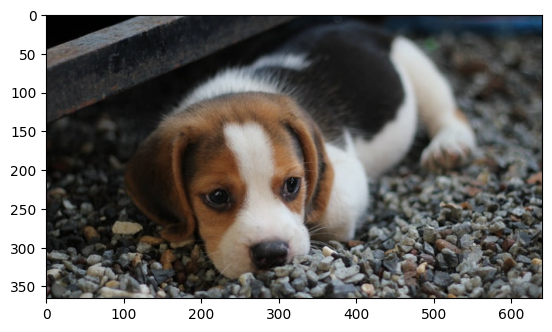

In [6]:
# OpenCV는 BGR형식으로 이미지 처리
# Matplotlib는 RGB형식으로 이미지 처리

img = cv2.imread(str(Image_Path))

img_rgb = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB       # BGR 형식 -> RGB 형식
)
plt.imshow(img_rgb)
plt.show()

(366, 640, 3)


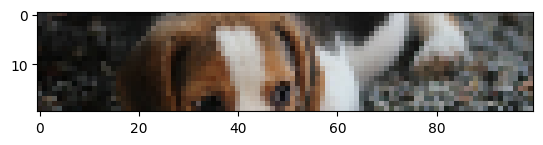

In [9]:
print(img_rgb.shape)
h, w = img_rgb.shape[:2]

slice_img = img_rgb[
    h//3 : h//3 * 2,
    0 : w
]

# 원본 사진에 있어서 아래의 영역에 대해 모자이크 처리

# 366*640 -> 20*100 배열 크기 변환
slice_img = cv2.resize(slice_img, (100, 20))

plt.imshow(slice_img)
plt.show()

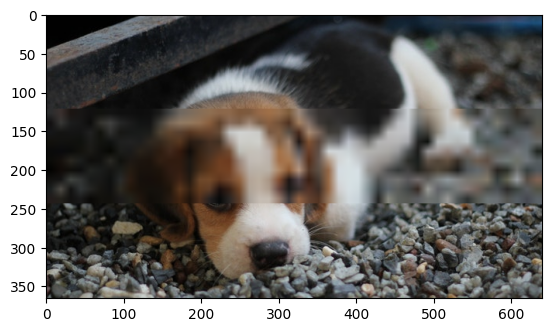

In [20]:
# 1. 높이 기준으로, 3등분한 사진 3개 만들기
top = img_rgb[
    0 : h//3,
    0 : w
]
middle = img_rgb[
    h//3 : h//3*2,
    0 : w
]
bottom = img_rgb[
    h//3*2 : h,
    0 : w
]

# 2. middle에 있어, 모자이크 처리 (resize())
middle_mosaic = cv2.resize(middle, (50, 10))      # resize(이미지, (가로, 세로))

# top, bottom :: (너비) 640
# middle_mosaic :: (너비) 50 -> 640 변경
middle_result = cv2.resize(middle_mosaic, (w, h//3))

# 3. top + middle + bottom 위아래로 연결  -> np.concatenate()
result = np.concatenate((top, middle_result, bottom))

plt.imshow(result)
plt.show()